In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats



In [2]:
data = {
    "User_ID": range(1, 101),
    "Group": ["Control"] * 50 + ["Treatment"] * 50,
    "Purchase_Amount": [
        420, 450, 390, 480, 510, 430, 460, 440, 500, 470,
        410, 450, 490, 520, 400, 460, 480, 430, 510, 440,
        470, 450, 420, 500, 460, 430, 490, 450, 470, 410,
        520, 440, 480, 460, 430, 500, 450, 470, 420, 490,
        440, 460, 510, 430, 480, 450, 470, 420, 500, 460,
        
        500, 530, 550, 520, 580, 540, 510, 560, 590, 530,
        550, 520, 570, 540, 510, 580, 560, 530, 550, 600,
        520, 570, 540, 560, 590, 530, 550, 520, 580, 540,
        560, 590, 510, 570, 550, 530, 580, 560, 540, 590,
        520, 550, 570, 530, 580, 560, 540, 590, 550, 570
    ]
}

df = pd.DataFrame(data)

df.head()

,User_ID,Group,Purchase_Amount
0,1,Control,420
1,2,Control,450
2,3,Control,390
3,4,Control,480
4,5,Control,510


In [3]:
print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Shape of dataset: (100, 3)

Column names:
Index(['User_ID', 'Group', 'Purchase_Amount'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User_ID          100 non-null    int64 
 1   Group            100 non-null    object
 2   Purchase_Amount  100 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 2.5+ KB


In [4]:
#Check Missing Values and Duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
User_ID            0
Group              0
Purchase_Amount    0
dtype: int64

Duplicate rows:
0


In [5]:
#Define Control and Treatment Groups
control = df[df["Group"] == "Control"]["Purchase_Amount"]
treatment = df[df["Group"] == "Treatment"]["Purchase_Amount"]

print("Control group size:", len(control))
print("Treatment group size:", len(treatment))

Control group size: 50
Treatment group size: 50


In [6]:
#Descriptive Statistics
summary = df.groupby("Group")["Purchase_Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

summary

,count,mean,median,std,min,max
Group,,,,,,
Control,50,459.4,460.0,32.727072,390,520
Treatment,50,551.2,550.0,25.685698,500,600


In [7]:
#Compare the Group Means
control_mean = control.mean()
treatment_mean = treatment.mean()

difference = treatment_mean - control_mean
percentage_change = (difference / control_mean) * 100

print("Control Mean:", round(control_mean, 2))
print("Treatment Mean:", round(treatment_mean, 2))
print("Difference:", round(difference, 2))
print("Percentage Change:", round(percentage_change, 2), "%")

Control Mean: 459.4
Treatment Mean: 551.2
Difference: 91.8
Percentage Change: 19.98 %


<Figure size 800x500 with 0 Axes>

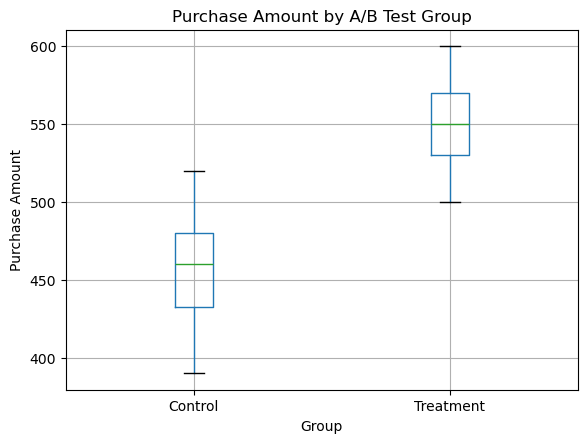

In [8]:
#Visualize the Groups
plt.figure(figsize=(8, 5))

df.boxplot(column="Purchase_Amount", by="Group")

plt.title("Purchase Amount by A/B Test Group")
plt.suptitle("")
plt.xlabel("Group")
plt.ylabel("Purchase Amount")

plt.show()

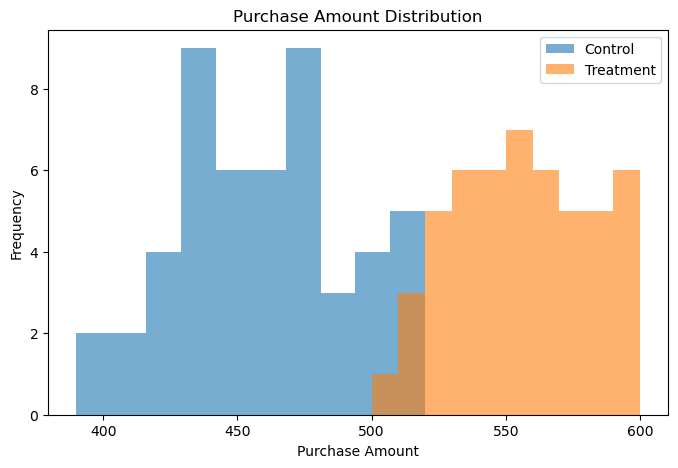

In [9]:
#Distribution Comparison
plt.figure(figsize=(8, 5))

plt.hist(control, alpha=0.6, label="Control")
plt.hist(treatment, alpha=0.6, label="Treatment")

plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.title("Purchase Amount Distribution")
plt.legend()

plt.show()

In [10]:
#Perform Statistical Test
test_result = stats.ttest_ind(
    control,
    treatment,
    equal_var=False
)

print("T-statistic:", test_result.statistic)
print("P-value:", test_result.pvalue)

T-statistic: -15.602787430215834
P-value: 1.115400830940751e-27


In [11]:
#Make the Statistical Decision
alpha = 0.05
p_value = test_result.pvalue

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("There is statistically significant evidence of a difference between the groups.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("There is not enough statistical evidence of a difference between the groups.")

Reject the Null Hypothesis.
There is statistically significant evidence of a difference between the groups.


In [12]:
#Calculate Effect Size
pooled_std = np.sqrt(
    ((len(control) - 1) * control.std()**2 +
     (len(treatment) - 1) * treatment.std()**2)
    / (len(control) + len(treatment) - 2)
)

cohens_d = (treatment.mean() - control.mean()) / pooled_std

print("Cohen's d:", round(cohens_d, 3))

Cohen's d: 3.121


In [13]:
#Confidence Interval
result = stats.ttest_ind(
    treatment,
    control,
    equal_var=False
)

ci = result.confidence_interval(confidence_level=0.95)

print("95% Confidence Interval:")
print("Lower:", round(ci.low, 2))
print("Upper:", round(ci.high, 2))

95% Confidence Interval:
Lower: 80.12
Upper: 103.48


In [14]:
#Create Final Results Table
results = pd.DataFrame({
    "Metric": [
        "Control Mean",
        "Treatment Mean",
        "Mean Difference",
        "Percentage Change",
        "T-statistic",
        "P-value",
        "Cohen's d"
    ],
    "Value": [
        control_mean,
        treatment_mean,
        difference,
        percentage_change,
        test_result.statistic,
        test_result.pvalue,
        cohens_d
    ]
})

results

,Metric,Value
0,Control Mean,4.594000e+02
1,Treatment Mean,5.512000e+02
2,Mean Difference,9.180000e+01
3,Percentage Change,1.998259e+01
4,T-statistic,-1.560279e+01
5,P-value,1.115401e-27
6,Cohen's d,3.120557e+00
